# Contract, timestamp and market-regime audit
Frozen study eed008040d6c6d18. Post-study evidence review, hypothetical fills.


In [1]:
from pathlib import Path
import os,sys,html
root=Path.cwd()
if not (root/'carry').exists():root=root.parent
os.chdir(root)
sys.path.insert(0,str(root))
def show_svg(svg):
    if '_emit_data' in globals():_emit_data({'image/svg+xml':svg})
    else:
        from IPython.display import display,SVG
        display(SVG(svg))
def show_table(headers,rows):
    markup='<table><thead><tr>'+''.join('<th>'+html.escape(str(v))+'</th>' for v in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+html.escape(str(v))+'</td>' for v in row)+'</tr>' for row in rows)+'</tbody></table>'
    if '_emit_data' in globals():_emit_data({'text/html':markup})
    else:
        from IPython.display import display,HTML
        display(HTML(markup))


## Question and evidence contract
Can the 2025 BTC/ETH streams support a settlement-level study? Inputs are the published data audit and post-study diagnostics. Raw/normalized inputs remain private. Funding units are decimal per settlement; the tables below use basis points. Run: `eed008040d6c6d18`. These descriptive diagnostics were added after the holdout was consumed and do not select new models.

In [2]:
import csv,json,math,statistics
from pathlib import Path
from carry.figures import lines,bars
from carry.engine import Config,replay,stress_case
from carry.run import sample,forecast_comparison,summarize,golden_case

def read_csv(name):
    with Path(name).open() as f:return list(csv.DictReader(f))


In [3]:
audit=json.loads(Path('artifacts/market/data_audit.json').read_text())
show_table(['Asset','Events','Missing','Duplicates','Max timestamp offset (ms)'],[[r['symbol'],r['events'],r['missing'],r['duplicates'],r['max_quote_age_ms']] for r in audit['coverage']])
assert all(r['events']==1095 and r['missing']==0 and r['duplicates']==0 for r in audit['coverage'])

Asset,Events,Missing,Duplicates,Max timestamp offset (ms)
BTCUSDT,1095,0,0,16
ETHUSDT,1095,0,0,16


## Timestamp decision
Actual funding milliseconds are retained. Executable references are nominal 8-hour bar opens, up to 16 ms earlier. This is a sampled execution assumption, not a synchronized order-book quote. Missing funding is never filled with zero. Current contract filters do not establish 2025 fee or margin tiers.

In [4]:
diagnostics=read_csv('artifacts/review/funding_diagnostics.csv')
show_table(['Asset','Mean funding (bps)','5th percentile','95th percentile','Negative events %','Longest negative run','Lag-1 correlation'],[[r['symbol'],*[round(float(r[k]),4) for k in ('funding_mean_bps','funding_p05_bps','funding_p95_bps')],round(float(r['negative_fraction'])*100,2),r['longest_negative_run'],round(float(r['funding_lag1_correlation']),3)] for r in diagnostics])

Asset,Mean funding (bps),5th percentile,95th percentile,Negative events %,Longest negative run,Lag-1 correlation
BTCUSDT,0.4682,-0.2417,1.0,12.88,10,0.553
ETHUSDT,0.4501,-0.2633,1.0,16.16,5,0.53


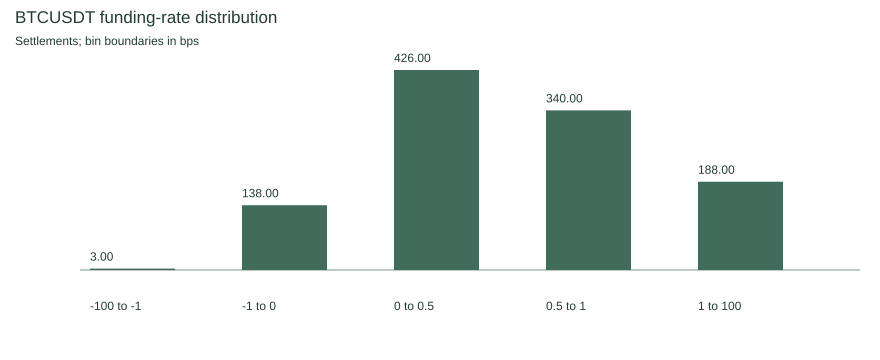

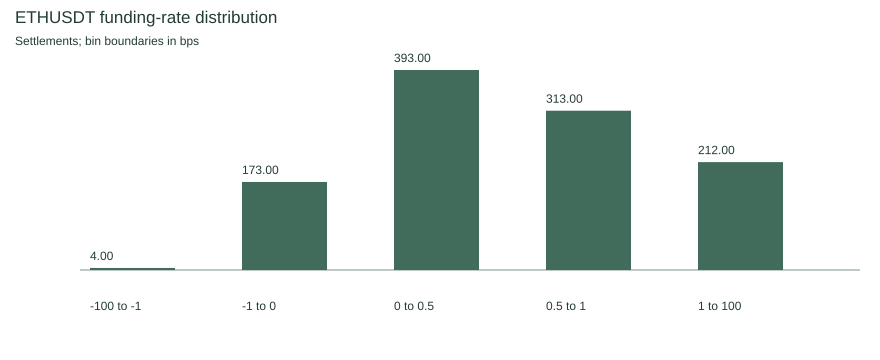

In [5]:
bins=read_csv('artifacts/review/funding_histogram.csv')
for symbol in ('BTCUSDT','ETHUSDT'):
    values=[r for r in bins if r['symbol']==symbol]
    show_svg(bars(symbol+' funding-rate distribution',[r['bin'] for r in values],[int(r['count']) for r in values],'Settlements; bin boundaries in bps'))
    assert sum(int(r['count']) for r in values)==1095

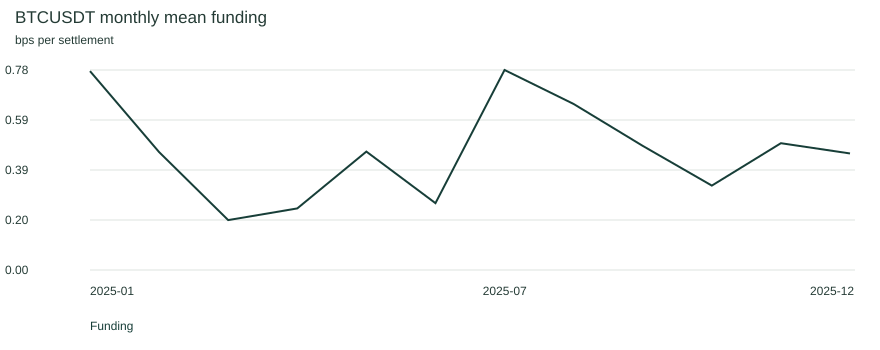

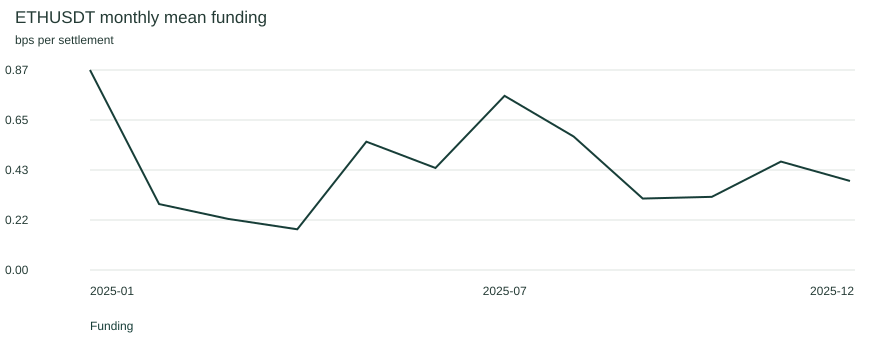

Asset,Median basis (bps),5th percentile,95th percentile,Funding / basis correlation
BTCUSDT,-4.451,-5.959,-2.326,0.445
ETHUSDT,-4.506,-5.99,-2.395,0.39


In [6]:
regimes=read_csv('artifacts/review/monthly_regimes.csv')
for symbol in ('BTCUSDT','ETHUSDT'):
    rs=[r for r in regimes if r['symbol']==symbol]
    show_svg(lines(symbol+' monthly mean funding',[r['month'] for r in rs],{'Funding':[float(r['mean_funding_bps']) for r in rs]},'bps per settlement'))
show_table(['Asset','Median basis (bps)','5th percentile','95th percentile','Funding / basis correlation'],[[r['symbol'],*[round(float(r[k]),3) for k in ('basis_median_bps','basis_p05_bps','basis_p95_bps','funding_basis_correlation')]] for r in diagnostics])

## Interpretation and exclusions
Positive average funding coexists with negative settlements and serial dependence. Persistence motivates testing a smoother forecast but does not establish net profitability. Basis uses traded perp / spot references and remains distinct from the settlement mark. Correlations are contemporaneous descriptions, not causal or out-of-sample signals. No venue, asset or period is removed based on these plots.

In [7]:
print('Funding sign convention: short payment = -signed perp units × settlement mark × rate.')
print('Independent case:',golden_case())
print('Retained universe: BTCUSDT and ETHUSDT; all 1,095 observed events per asset.')

Funding sign convention: short payment = -signed perp units × settlement mark × rate.
Independent case: {'pnl': -2860.824999999997, 'equity': 97139.175, 'funding': 0.5499999999999972, 'delta': -275.0}
Retained universe: BTCUSDT and ETHUSDT; all 1,095 observed events per asset.


## Conclusion and artifacts
Coverage supports the fixed sampled study. It does not support an order-book execution claim or exact liquidation reconstruction. Audit: `artifacts/market/data_audit.json`. Descriptive tables: `artifacts/review/funding_diagnostics.csv`, `monthly_regimes.csv`, `funding_histogram.csv`. Private-input rebuild: `python3 -m scripts.prepare_review`.